# Lab 01 — Descriptive Statistics in Python
## ✅ FULL SOLUTION (Instructor Version)
**Department of Applied Mathematics and Statistics (AMS), Institute of Technology of Cambodia**
Asst. Prof. Dr. PHAUK Sokkhey

---

### Learning objectives
By the end of this lab you will be able to:
1. Classify variables as **nominal, ordinal, interval, or ratio**.
2. Compute and interpret **mean, median, mode, range, variance, standard deviation, IQR, CV, skewness and kurtosis** using built-in functions.
3. Build a **five-number summary**, detect outliers with the $1.5\times\text{IQR}$ rule, and draw a **boxplot**.
4. Summarise **categorical data** with a frequency table (frequency, percent, cumulative percent).

### Lab structure
| Part | Content | Status |
|---|---|---|
| A — Exercise 1 | Tensile strength of steel specimens (quantitative data) | Solved |
| A — Exercise 2 | Salaries of Company A vs B + marital-status table | Solved |
| B — Practice 1 | Test scores in English, Math, Physics | Solved |
| B — Practice 2 | Defect types and customer ratings on a production line | Solved |

### Formula reference (from Lecture 01)

| Measure | Population | Sample | Python |
|---|---|---|---|
| Mean | $\mu=\dfrac{\sum x_i}{N}$ | $\bar x=\dfrac{\sum x_i}{n}$ | `s.mean()` |
| Variance | $\sigma^2=\dfrac{\sum (x_i-\mu)^2}{N}$ | $s^2=\dfrac{\sum (x_i-\bar x)^2}{n-1}$ | `s.var(ddof=0)` / `s.var()` |
| Std. deviation | $\sigma=\sqrt{\sigma^2}$ | $s=\sqrt{s^2}$ | `s.std(ddof=0)` / `s.std()` |
| Coefficient of variation | | $CV=\dfrac{s}{\bar x}\times100\%$ | `s.std()/s.mean()*100` |
| IQR | | $Q_3-Q_1$ | `s.quantile(.75)-s.quantile(.25)` |
| Pearson skewness | | $Sk=\dfrac{3(\bar x-\text{median})}{s}$ | — |
| Kurtosis | | normal $=3$ (excess $=0$) | `stats.kurtosis(x, fisher=False)` |

> ⚠️ **Watch the defaults:** `pandas` uses `ddof=1` (sample), `numpy` uses `ddof=0` (population). `pandas.Series.kurt()` returns **excess** kurtosis (normal $=0$), not the lecture's scale (normal $=3$).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (8, 4)

---
# Part A — Worked Exercises (with Solutions)

## Exercise 1 — Tensile Strength of Steel Specimens
A materials lab tested 20 steel rods. Tensile strength (MPa) is recorded below.
The last specimen was mis-recorded during data entry (an **outlier**).

**Tasks**
1. Identify the level of measurement of `strength`.
2. Compute mean, median, mode.
3. Compute range, sample variance, sample SD, CV, and IQR.
4. Build the five-number summary, find outliers with the $1.5\times\text{IQR}$ rule, and draw a boxplot.
5. Compute skewness and kurtosis and interpret the shape.
6. Remove the outlier and compare: which measures are **robust**?

In [2]:
strength = pd.Series([412, 425, 418, 430, 421, 415, 428, 419, 433, 422,
                      417, 426, 420, 424, 431, 418, 423, 427, 416, 610],
                     name="strength_MPa")
strength.describe()

count     20.000
mean     431.750
std       42.337
min      412.000
25%      418.000
50%      422.500
75%      427.250
max      610.000
Name: strength_MPa, dtype: float64

**1. Level of measurement.** Tensile strength has a true zero (0 MPa = no strength) and ratios are meaningful (400 MPa is twice 200 MPa) → **ratio**, quantitative, continuous.

**2. Measures of central tendency**

In [3]:
center = pd.Series({
    "Mean":   strength.mean(),
    "Median": strength.median(),
    "Mode":   strength.mode().tolist(),
})
center

Mean      431.75
Median     422.5
Mode       [418]
dtype: object

The mean (≈ 431.8) is pulled above the median (422.5) by the 610 MPa outlier. The mode (418) is not very informative for continuous data.

**3. Measures of variability**

In [4]:
Q1, Q3 = strength.quantile([0.25, 0.75])
spread = pd.Series({
    "Range":            strength.max() - strength.min(),
    "Variance (s^2)":   strength.var(),           # ddof=1 → sample
    "Variance (σ^2)":   strength.var(ddof=0),     # population
    "SD (s)":           strength.std(),
    "CV (%)":           strength.std() / strength.mean() * 100,
    "IQR":              Q3 - Q1,
})
spread

Range              198.000
Variance (s^2)    1792.408
Variance (σ^2)    1702.787
SD (s)              42.337
CV (%)               9.806
IQR                  9.250
dtype: float64

**4. Five-number summary, outlier fences, boxplot**

Lower fence $=Q_1-1.5\,\text{IQR}$, Upper fence $=Q_3+1.5\,\text{IQR}$.

Min       412.00
Q1        418.00
Median    422.50
Q3        427.25
Max       610.00
dtype: float64 
Fences: [404.12, 441.12]
Outliers: [610]


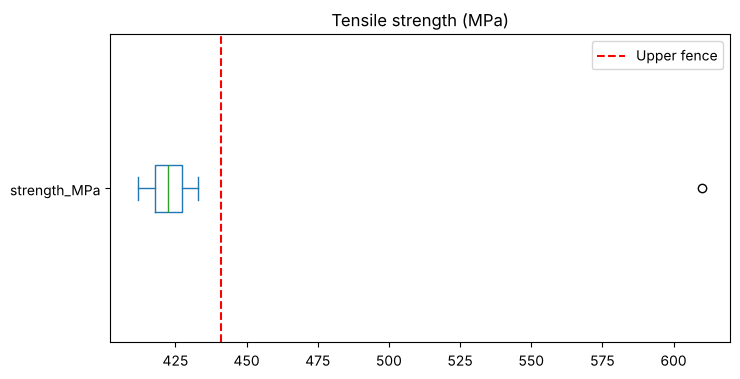

In [ ]:
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

five_num = pd.Series({"Min": strength.min(), "Q1": Q1, "Median": strength.median(),
                      "Q3": Q3, "Max": strength.max()})
print(five_num, f"\nFences: [{lower:.2f}, {upper:.2f}]")
print("Outliers:", strength[(strength < lower) | (strength > upper)].tolist())

strength.plot.box(vert=False, title="Tensile strength (MPa)")
plt.axvline(upper, ls="--", c="red", label="Upper fence"); plt.legend(); plt.show()

**5. Shape: skewness and kurtosis**

In [6]:
shape = pd.Series({
    "Pearson skew 3(mean-median)/s": 3 * (strength.mean() - strength.median()) / strength.std(),
    "Moment skew (scipy)":           stats.skew(strength),
    "Kurtosis (normal = 3)":         stats.kurtosis(strength, fisher=False),
    "Excess kurtosis (pandas)":      strength.kurt(),
})
shape

Pearson skew 3(mean-median)/s     0.655
Moment skew (scipy)               4.007
Kurtosis (normal = 3)            17.417
Excess kurtosis (pandas)         19.171
dtype: float64

**Interpretation.** Moment skewness ≈ 4 $>1$ → **highly right-skewed**. Kurtosis ≈ 17 $\gg 3$ → **leptokurtic** (heavy tail), driven entirely by one extreme value.

> Note that Pearson's formula gives only ≈ 0.66 here: it uses the median, which ignores the extreme value, so it *understates* skewness caused by a single outlier. Software (`scipy`, `pandas`, Excel `SKEW`) uses the moment-based definition.

**6. Effect of removing the outlier**

In [7]:
clean = strength[strength.between(lower, upper)]
compare = pd.DataFrame({
    "With outlier":    [strength.mean(), strength.median(), strength.std(), Q3 - Q1, stats.skew(strength)],
    "Without outlier": [clean.mean(), clean.median(), clean.std(),
                        clean.quantile(.75) - clean.quantile(.25), stats.skew(clean)],
}, index=["Mean", "Median", "SD", "IQR", "Skewness"])
compare["Change"] = compare["Without outlier"] - compare["With outlier"]
compare

,With outlier,Without outlier,Change
Mean,431.750,422.368,-9.382
Median,422.500,422.000,-0.500
SD,42.337,5.823,-36.513
IQR,9.250,8.500,-0.750
Skewness,4.007,0.141,-3.866


**Conclusion.** One bad value moved the mean by ≈ 9.4 MPa and inflated the SD about seven-fold (5.8 → 42.3), while the **median and IQR barely changed** — they are *robust* measures. For engineering QC data with possible recording errors, report the median and IQR alongside the mean and SD.

---
## Exercise 2 — "The Deceptive Average" + Categorical Summary

### 2a. Company A vs Company B
Both companies report a mean salary of \$70,000 (Lecture slide *Central Tendency*).
- Company A: 50 employees each earn \$70,000.
- Company B: 25 earn \$35,000 and 25 earn \$105,000.

**Tasks:** Compare mean, median, SD, CV and range. Which company would you join?

In [8]:
salary = pd.DataFrame({
    "Company A": np.repeat(70_000, 50),
    "Company B": np.repeat([35_000, 105_000], 25),
})

summary = salary.agg(["mean", "median", "std", "min", "max"]).T
summary["CV (%)"] = summary["std"] / summary["mean"] * 100
summary["Range"]  = summary["max"] - summary["min"]
summary

,mean,median,std,min,max,CV (%),Range
Company A,70000.0,70000.0,0.000,70000.0,70000.0,0.000,0.0
Company B,70000.0,70000.0,35355.339,35000.0,105000.0,50.508,70000.0


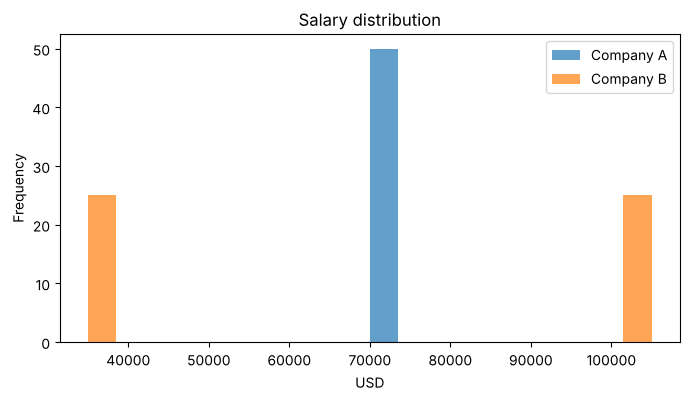

In [9]:
salary.plot.hist(bins=20, alpha=0.7, title="Salary distribution"); plt.xlabel("USD"); plt.show()

**Interpretation.** Same mean and median, but Company A has SD = 0 while Company B has SD ≈ \$35,355 (CV ≈ 50%). A new employee at B has a 50% chance of earning only half the "average". Note also that B's median (\$70,000) is the average of the two middle values — **no one at B actually earns it**. **A measure of center is incomplete without a measure of spread.**

### 2b. Frequency table for a nominal variable
Reproduce the lecture's marital-status table for a sample of 80 people.

In [10]:
marital = pd.Series(["Single"] * 44 + ["Married"] * 29 + ["Other"] * 7, name="Marital status")

freq = marital.value_counts().to_frame("Frequency")
freq["Percent"]            = marital.value_counts(normalize=True) * 100
freq["Cumulative Percent"] = freq["Percent"].cumsum()
freq.loc["Total"] = [freq["Frequency"].sum(), 100, np.nan]
freq.astype({"Frequency": int}).round(1)

,Frequency,Percent,Cumulative Percent
Marital status,,,
Single,44,55.0,55.0
Married,29,36.2,91.2
Other,7,8.8,100.0
Total,80,100.0,NaN


Mode: Single


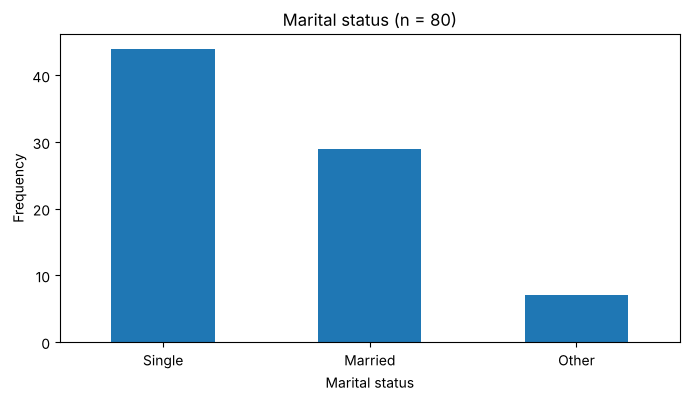

In [11]:
print("Mode:", marital.mode()[0])
marital.value_counts().plot.bar(rot=0, title="Marital status (n = 80)"); plt.ylabel("Frequency"); plt.show()

**Note.** For a **nominal** variable, the mean and median are meaningless; the **mode** and the frequency/percent table are the appropriate summaries.

---
# Part B — Practice Exercises — Solutions

## Practice 1 — Test Scores in Three Subjects
This mirrors the lecture slide *Standard Deviation Interpretation*. Scores for 300 students are generated below (do **not** change the seed).

**Tasks**
1. Compute mean, median, SD, CV, IQR, skewness and kurtosis (normal = 3) for each subject in **one table**.
2. Draw side-by-side boxplots and histograms.
3. List the outliers in each subject using the $1.5\times\text{IQR}$ rule.
4. Answer: *What does the SD tell you about students' performance in each test?*

In [12]:
rng = np.random.default_rng(2026)
scores = pd.DataFrame({
    "English": rng.normal(100, 7.5, 300).round(1),
    "Math":    rng.normal(100, 15.3, 300).round(1),
    "Physics": rng.normal(100, 30.8, 300).round(1),
})
scores.head()

,English,Math,Physics
0,94.1,100.7,128.3
1,101.8,84.1,96.2
2,85.8,116.6,122.2
3,110.5,124.5,49.0
4,104.8,101.0,91.9


In [13]:

# SOLUTION 1: summary table, one row per subject
q = scores.quantile([0.25, 0.75])
summary_scores = pd.DataFrame({
    "Mean":                  scores.mean(),
    "Median":                scores.median(),
    "SD":                    scores.std(),
    "CV (%)":                scores.std() / scores.mean() * 100,
    "IQR":                   q.loc[0.75] - q.loc[0.25],
    "Skewness":              scores.skew(),
    "Kurtosis (normal = 3)": scores.apply(stats.kurtosis, fisher=False),
})
summary_scores.round(2)


,Mean,Median,SD,CV (%),IQR,Skewness,Kurtosis (normal = 3)
English,100.61,100.75,7.98,7.93,10.70,0.06,3.27
Math,99.97,100.55,15.90,15.90,22.05,0.06,3.11
Physics,101.19,101.10,30.81,30.45,41.18,-0.24,2.94


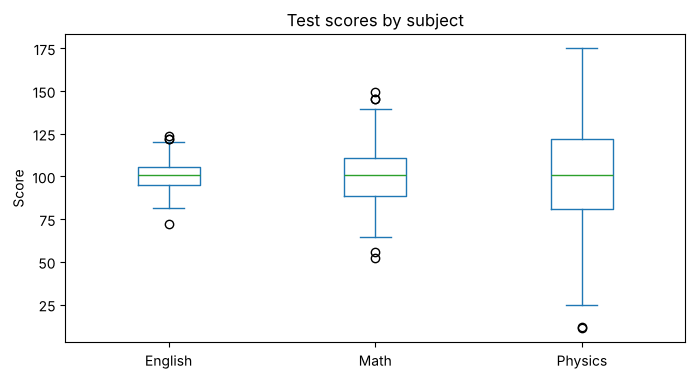

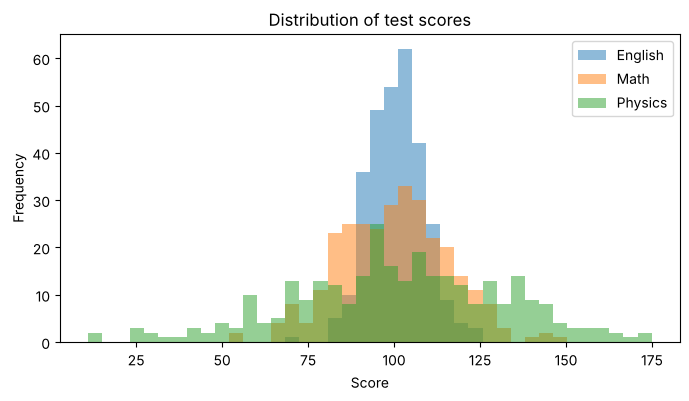

In [14]:

# SOLUTION 2: boxplots and overlaid histograms
scores.plot.box(title="Test scores by subject"); plt.ylabel("Score"); plt.show()

scores.plot.hist(bins=40, alpha=0.5, title="Distribution of test scores")
plt.xlabel("Score"); plt.show()


In [15]:

# SOLUTION 3: 1.5×IQR outliers per subject
for col in scores.columns:
    Q1, Q3 = scores[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lo, hi = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    out = scores[col][(scores[col] < lo) | (scores[col] > hi)]
    print(f"{col:8s} fences [{lo:6.2f}, {hi:6.2f}]  outliers ({len(out)}): {sorted(out.tolist())}")


English  fences [ 78.95, 121.75]  outliers (4): [71.9, 121.9, 122.2, 123.6]
Math     fences [ 55.68, 143.88]  outliers (5): [52.4, 55.6, 145.4, 145.4, 149.5]
Physics  fences [ 19.19, 183.89]  outliers (2): [11.0, 11.9]



**SOLUTION 4 — Interpretation**

All three tests have almost the same center (mean ≈ median ≈ 100), skewness close to 0 and kurtosis close to 3, so each is roughly **symmetric and normal-shaped**. They differ only in **spread**: SD ≈ 8 (English), ≈ 16 (Math) and ≈ 31 (Physics), and the CV and IQR grow in the same proportion.
- **English:** scores are tightly clustered; most students perform similarly, so the test separates students only weakly.
- **Math:** moderate spread; a typical student scores within about ±16 points of the average.
- **Physics:** very wide spread; performance is highly uneven, with some students far ahead and others far behind. An "average of 100" describes the Physics class much less well than the English class.

The handful of 1.5×IQR outliers in each subject (2–5 values out of 300) is about what a normal distribution produces by chance, so they are **not** data errors and should not be removed.


---
## Practice 2 — Quality Control on a Production Line
An inspector recorded each defective unit's **defect type** (nominal) and the customer's **rating** of the replacement service (ordinal: *Bad < Good < Excellent*).

**Tasks**
1. State the level of measurement of each variable.
2. Build a frequency table for `defect` with Frequency, Percent and Cumulative Percent, **sorted from most to least frequent** (a Pareto table).
3. Find the mode of each variable and draw a bar chart of `defect`.
4. Convert `rating` to an **ordered categorical** and find its median category.
5. Answer: *Why can we report a median for `rating` but not for `defect`?*

In [16]:
rng = np.random.default_rng(15)
qc = pd.DataFrame({
    "defect": rng.choice(["Scratch", "Crack", "Misalignment", "Porosity", "Dent"],
                         size=120, p=[0.35, 0.10, 0.25, 0.20, 0.10]),
    "rating": rng.choice(["Bad", "Good", "Excellent"], size=120, p=[0.2, 0.5, 0.3]),
})
qc.head()

,defect,rating
0,Misalignment,Good
1,Porosity,Good
2,Scratch,Bad
3,Scratch,Good
4,Misalignment,Excellent



**SOLUTION 1 — Level of measurement**
- `defect`: **nominal** — categories with names only, no natural order.
- `rating`: **ordinal** — ordered categories (*Bad < Good < Excellent*), but the gaps between them are not measurable.


In [17]:

# SOLUTION 2: Pareto table (value_counts already sorts most → least frequent)
pareto = qc["defect"].value_counts().to_frame("Frequency")
pareto["Percent"]            = qc["defect"].value_counts(normalize=True) * 100
pareto["Cumulative Percent"] = pareto["Percent"].cumsum()
pareto.round(1)


,Frequency,Percent,Cumulative Percent
defect,,,
Scratch,40,33.3,33.3
Misalignment,32,26.7,60.0
Porosity,26,21.7,81.7
Dent,12,10.0,91.7
Crack,10,8.3,100.0


Mode of defect: Scratch
Mode of rating: Good


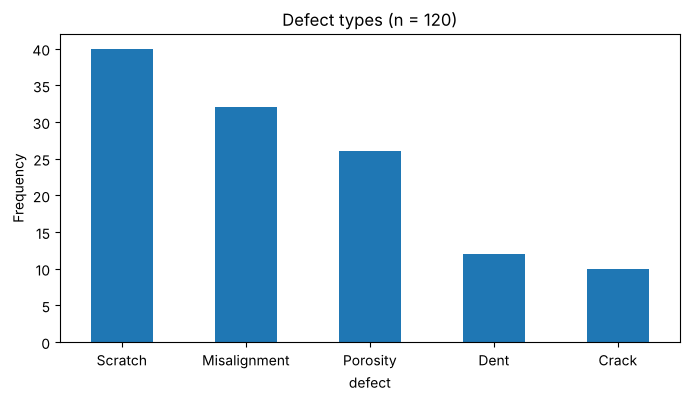

In [18]:

# SOLUTION 3: modes and bar chart
print("Mode of defect:", qc["defect"].mode()[0])
print("Mode of rating:", qc["rating"].mode()[0])

qc["defect"].value_counts().plot.bar(rot=0, title="Defect types (n = 120)")
plt.ylabel("Frequency"); plt.show()


In [19]:

# SOLUTION 4: ordered categorical and its median
qc["rating"] = pd.Categorical(qc["rating"], categories=["Bad", "Good", "Excellent"], ordered=True)

median_code = int(np.median(qc["rating"].cat.codes))
print("Counts:\n", qc["rating"].value_counts(sort=False), sep="")
print("Median rating:", qc["rating"].cat.categories[median_code])
print("Min / Max:", qc["rating"].min(), "/", qc["rating"].max())   # valid because the category is ordered


Counts:
rating
Bad          18
Good         67
Excellent    35
Name: count, dtype: int64
Median rating: Good
Min / Max: Bad / Excellent



**SOLUTION 5 — Interpretation**

The median is the value in the **middle after sorting**, so it needs an order. `rating` has a natural order (*Bad < Good < Excellent*), so we can sort the 120 ratings and read off the middle one: **Good**. `defect` has no order (is a "Crack" more or less than a "Dent"?), so sorting is arbitrary and any "median" would change with the alphabet. For nominal data the only meaningful center is the **mode** (here, *Scratch*).

**Pareto reading:** Scratch, Misalignment and Porosity together account for ≈ 82% of all defects, so QC improvement effort should target those three first.
